### Week 4 - task
- student name : chanin jung (AI specialization)
- neptun code : Z5XBZP

### Assignment: Feature Selection + PCA
- Dataset: Use the same numeric/tabular dataset you used previously (the one from the earlier notebook/lecture). Do not use textual data.

- Task type: Supervised learning (classification or regression depending on your dataset’s target).

- Submission: One Jupyter Notebook (.ipynb) with code, plots, and short written answers (1–3 sentences each).

### Constraints
- Use a clean train/test split consistently across methods.
- Use a pipeline wherever scaling is needed (especially for PCA and distance/regularization-based models).
- All comparisons must use the same evaluation metric (choose one and keep it consistent).
### Goal
- Compare four dimensionality-reduction / feature-selection approaches: Sequential Forward Selection (SFS), Sequential Backward Selection (SBS), Bidirectional Selection, and PCA, and determine which produces the best performance vs. simplicity trade-off.

### Part A : Setup + Baseline
- Load the dataset and define:
- X = feature matrix (numeric features only; encode categories if needed)
- y = target
- Create a baseline model using all features.
- Classification: Logistic Regression
- Regression: Linear Regression
- Evaluate baseline with your chosen metric (examples):
- Classification: accuracy, Recall, F1-score
- Regression: RMSE, MAE, R²
- Write 1–2 sentences: Why did you choose this metric for your problem?

### Part B: Sequential Feature Selection
- Use cross-validation for selection (recommended: 5-fold CV). Keep the same estimator across SFS/SBS/Bidirectional. If your estimator requires scaling (e.g., logistic regression, ridge), build a Pipeline with scaling.

##### B1. Sequential Forward Selection (SFS)
- Run SFS to select k features (choose k = 5 OR k = round(0.25 × number_of_features)).
- Report:
- Selected feature list
- CV score during selection
- Test-set score using only the selected features
##### B2. Sequential Backward Selection (SBS)
- Run SBS to select the same k features.
- Report the same items as SFS.
- Write 1–2 sentences: Did SBS pick a very different set than SFS? Why might that happen?
##### B3. Bidirectional Selection
Run bidirectional selection (forward + backward steps) to select the same k features.
Report:
- Selected feature list
- CV score during selection
- Test-set score using only the selected features
- Write 1–2 sentences: When might bidirectional selection be preferable to pure forward/backward?

### Part C: PCA as Dimensionality Reduction
##### C1. Fit PCA (with scaling)
Build a pipeline:
- Imputer (if needed)
- Scaler (standardization)
- PCA
- Estimator (same model family as baseline if possible)
- Plot the cumulative explained variance vs number of components.
- Choose number of components using one rule:
- Minimum components to reach 90% explained variance, OR
- Use an “elbow” point you justify briefly
##### C2. Evaluate PCA model
Train and evaluate the model using your chosen number of PCA components.
- Report:
- components used
- Explained variance achieved
- CV score (optional but recommended)
- Test-set score
- Write 2 sentences: One benefit and one drawback of PCA compared to selecting original features.

### Required Deliverables
- Baseline performance using all features.
- For each method (SFS, SBS, Bidirectional, PCA):
- Selected features (or #components for PCA)
- Evaluation metric score on test set
- Short interpretation (1–3 sentences)
- At least 1 plot: cumulative explained variance curve for PCA.
- A final comparison table summarizing results.

### Final answer (3–5 sentences):
- Which approach would you recommend for this dataset and why (performance + interpretability + compute time)?

### Optional (if time remains)
- Show runtime (rough timing) for SFS vs SBS vs Bidirectional and comment on feasibility as feature count grows.
- For PCA, visualize the first two principal components colored by the target (if classification).

### Choosed datas is about "music" from spotify
- Dataset: Use the same numeric/tabular dataset you used previously (the one from the earlier notebook/lecture). Do not use textual data.
- Task type: Supervised learning (classification or regression depending on your dataset’s target).
- **Chosen task:** multi-class **classification** — predict `track_genre` among 8 representative genres (`acoustic, classical, country, edm, heavy-metal, hip-hop, jazz, reggae`) from numeric features only.

In [1]:
!pip install --upgrade kagglehub


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# ==========================================
# Part A: Quick Data Audit
# ==========================================
import pandas as pd
import numpy as np
import kagglehub
from IPython.display import display

# 1. Load the dataset
#    Try the Kaggle download first; fall back to a local copy for offline runs.
try:
    dataset_path = kagglehub.dataset_download("maharshipandya/-spotify-tracks-dataset")
    df = pd.read_csv(f"{dataset_path}/dataset.csv", encoding="latin-1")
    print("Loaded dataset via kagglehub.")
except Exception as e:
    print("kagglehub unavailable -> using local spotify_data.csv:", e)
    df = pd.read_csv("spotify_data.csv", encoding="latin-1")
    df.columns = [c.replace("\ufeff", "").replace("\u00ef\u00bb\u00bf", "") for c in df.columns]

# Clean unnecessary index column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 2. Print shape
print("=== 1. Dataset Shape ===")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}\n")

# 3. Create a professional Data Audit Summary Table
print("=== 2. Data Audit Summary (Types & Missing Values) ===")
audit_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Missing Values': df.isnull().sum(),
    'Missing (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Unique Values': df.nunique()
})
display(audit_summary)

# 4. Basic descriptive stats
print("\n=== 3. Descriptive Stats for Numeric Columns ===")
display(df.describe().round(2))

Loaded dataset via kagglehub.
=== 1. Dataset Shape ===
Rows: 114000, Columns: 20

=== 2. Data Audit Summary (Types & Missing Values) ===


,Data Type,Missing Values,Missing (%),Unique Values
track_id,object,0,0.0,89741
artists,object,1,0.0,31437
album_name,object,1,0.0,46589
track_name,object,1,0.0,73608
popularity,int64,0,0.0,101
duration_ms,int64,0,0.0,50697
explicit,bool,0,0.0,2
danceability,float64,0,0.0,1174
energy,float64,0,0.0,2083
key,int64,0,0.0,12



=== 3. Descriptive Stats for Numeric Columns ===


,popularity,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature
count,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00,114000.00
mean,33.24,228029.15,0.57,0.64,5.31,-8.26,0.64,0.08,0.31,0.16,0.21,0.47,122.15,3.90
std,22.31,107297.71,0.17,0.25,3.56,5.03,0.48,0.11,0.33,0.31,0.19,0.26,29.98,0.43
min,0.00,0.00,0.00,0.00,0.00,-49.53,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,17.00,174066.00,0.46,0.47,2.00,-10.01,0.00,0.04,0.02,0.00,0.10,0.26,99.22,4.00
50%,35.00,212906.00,0.58,0.68,5.00,-7.00,1.00,0.05,0.17,0.00,0.13,0.46,122.02,4.00
75%,50.00,261506.00,0.70,0.85,8.00,-5.00,1.00,0.08,0.60,0.05,0.27,0.68,140.07,4.00
max,100.00,5237295.00,0.98,1.00,11.00,4.53,1.00,0.96,1.00,1.00,1.00,1.00,243.37,5.00


In [3]:
# ==========================================
# Part A: Setup + Baseline (Classification)
# ------------------------------------------
# Target (y)   : track_genre (8 representative genres) -> 8-class classification
# Features (X) : numeric features only (textual / ID columns dropped)
# Model        : Logistic Regression inside a StandardScaler pipeline
# Metric       : Accuracy (kept identical for SFS / SBS / Bidirectional / PCA)
#
# Why accuracy? The 8 chosen genres are perfectly balanced (1000 tracks each),
# so accuracy is a fair, interpretable metric; macro-F1 is also reported.
# ==========================================
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# 1) Drop textual / ID columns  (assignment: "Do not use textual data")
text_cols = ['track_id', 'artists', 'album_name', 'track_name']
df = df.drop(columns=text_cols)

# 2) Encode the only categorical feature: explicit (bool -> 0/1)
df['explicit'] = df['explicit'].astype(int)

# 3) Keep only 8 representative genres (balanced classification task)
GENRES = ['acoustic', 'classical', 'country', 'edm',
          'heavy-metal', 'hip-hop', 'jazz', 'reggae']
df = df[df['track_genre'].isin(GENRES)].copy()
print("Rows:", len(df), "| classes:", df['track_genre'].nunique())
print(df['track_genre'].value_counts())

# 4) y = target (classification) ; X = numeric features only
y = df['track_genre']
X = df.drop(columns=['track_genre'])

print("X shape:", X.shape)
print("Missing values in X:", X.isnull().sum().sum(), "-> no imputer needed")

# 5) Fixed train/test split -> reused by ALL methods for a fair comparison
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6) Baseline: Logistic Regression inside a scaling Pipeline
baseline = Pipeline([
    ('scaler', StandardScaler()),
    ('clf', LogisticRegression(max_iter=1000))
])
baseline.fit(X_train, y_train)

# 7) Evaluate with the ONE metric kept consistent across all methods: Accuracy
pred = baseline.predict(X_test)
acc = accuracy_score(y_test, pred)
f1  = f1_score(y_test, pred, average='macro')

print(f"\n=== Baseline (all {X.shape[1]} features) ===")
print(f"Accuracy (chosen metric): {acc:.4f}")
print(f"Macro-F1                : {f1:.4f}")

# 5-fold CV on the training set for stability
cv = cross_val_score(baseline, X_train, y_train, cv=5, scoring='accuracy')
print(f"5-fold CV Accuracy: {cv.mean():.4f} (+/- {cv.std():.4f})")

Rows: 8000 | classes: 8
track_genre
acoustic       1000
classical      1000
country        1000
edm            1000
heavy-metal    1000
hip-hop        1000
jazz           1000
reggae         1000
Name: count, dtype: int64
X shape: (8000, 15)
Missing values in X: 0 -> no imputer needed

=== Baseline (all 15 features) ===
Accuracy (chosen metric): 0.6212
Macro-F1                : 0.6201


5-fold CV Accuracy: 0.6267 (+/- 0.0136)


**Why this metric?** The 8 chosen genres are perfectly balanced (1000 tracks each), so no class dominates and plain **accuracy** is a fair, easy-to-interpret summary of overall correctness. I keep accuracy as the single metric for every method (baseline, SFS, SBS, Bidirectional, PCA) so the comparison is apples-to-apples; macro-F1 is reported alongside only as a sanity check.

### Part B: Sequential Feature Selection
All three methods use the **same estimator** (StandardScaler + LogisticRegression), the **same metric** (Accuracy), the **same 5-fold CV**, and the **same fixed train/test split** from Part A.

In [4]:
# ==========================================
# Part B - setup (shared by SFS / SBS / Bidirectional)
# ==========================================
import time
from sklearn.feature_selection import SequentialFeatureSelector

def make_estimator():
    return Pipeline([('scaler', StandardScaler()),
                     ('clf', LogisticRegression(max_iter=1000))])

def test_acc(cols):
    """Fit on the train set using only `cols`, return accuracy on the fixed test set."""
    model = make_estimator()
    model.fit(X_train[cols], y_train)
    return accuracy_score(y_test, model.predict(X_test[cols]))

# number of features to select: k = round(0.25 * n_features)
n_features = X.shape[1]
k = max(1, round(0.25 * n_features))
print(f"n_features = {n_features}  ->  k = {k}")

# baseline (all features) test accuracy, for reference in the final table
baseline_test_acc = test_acc(list(X.columns))
print(f"Baseline (all features) Test Accuracy: {baseline_test_acc:.4f}")

n_features = 15  ->  k = 4
Baseline (all features) Test Accuracy: 0.6212


##### B1. Sequential Forward Selection (SFS)

In [5]:
# ----- B1. Sequential Forward Selection (SFS) -----
t0 = time.time()
sfs = SequentialFeatureSelector(
    make_estimator(),
    n_features_to_select=k,
    direction='forward',
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
sfs.fit(X_train, y_train)
sfs_time = time.time() - t0

sfs_features = list(X_train.columns[sfs.get_support()])
sfs_cv_acc = cross_val_score(make_estimator(), X_train[sfs_features], y_train,
                             cv=5, scoring='accuracy').mean()
sfs_test_acc = test_acc(sfs_features)

print("SFS selected features:", sfs_features)
print(f"SFS CV Accuracy   : {sfs_cv_acc:.4f}")
print(f"SFS Test Accuracy : {sfs_test_acc:.4f}")
print(f"SFS runtime       : {sfs_time:.1f}s")

SFS selected features: ['popularity', 'danceability', 'speechiness', 'acousticness']
SFS CV Accuracy   : 0.5395
SFS Test Accuracy : 0.5238
SFS runtime       : 8.2s


**Interpretation:** SFS kept 4 of 15 features (`popularity, danceability, speechiness, acousticness`) with CV accuracy ≈ 0.54 and test accuracy ≈ 0.52. This is clearly **below** the all-feature baseline (0.62), so cutting down to 4 features costs real accuracy for this 8-class task.

##### B2. Sequential Backward Selection (SBS)

In [6]:
# ----- B2. Sequential Backward Selection (SBS) -----
t0 = time.time()
sbs = SequentialFeatureSelector(
    make_estimator(),
    n_features_to_select=k,
    direction='backward',
    scoring='accuracy',
    cv=5,
    n_jobs=-1
)
sbs.fit(X_train, y_train)
sbs_time = time.time() - t0

sbs_features = list(X_train.columns[sbs.get_support()])
sbs_cv_acc = cross_val_score(make_estimator(), X_train[sbs_features], y_train,
                             cv=5, scoring='accuracy').mean()
sbs_test_acc = test_acc(sbs_features)

print("SBS selected features:", sbs_features)
print(f"SBS CV Accuracy   : {sbs_cv_acc:.4f}")
print(f"SBS Test Accuracy : {sbs_test_acc:.4f}")
print(f"SBS runtime       : {sbs_time:.1f}s")

SBS selected features: ['popularity', 'danceability', 'speechiness', 'acousticness']
SBS CV Accuracy   : 0.5395
SBS Test Accuracy : 0.5238
SBS runtime       : 9.1s


**Interpretation:** SBS selected the **exact same 4 features** as SFS (`popularity, danceability, speechiness, acousticness`), giving identical CV/test accuracy. With only 15 features the search space is small, so forward and backward greedy search converge to the same optimum instead of diverging.

##### B3. Bidirectional Selection

In [7]:
# ----- B3. Bidirectional Selection (custom: forward + backward steps) -----
# Note: sklearn's SequentialFeatureSelector only supports 'forward' or 'backward',
# so we implement a bidirectional (stepwise) search manually.
def bidirectional_selection(X, y, k, cv=5, max_iter=50):
    est = make_estimator()
    def cv_acc(cols):
        if not cols:
            return -np.inf
        return cross_val_score(est, X[cols], y, cv=cv,
                               scoring='accuracy').mean()
    selected, remaining = [], list(X.columns)
    # forward steps until we have k features
    while len(selected) < k:
        best_f, best_s = None, -np.inf
        for f in remaining:
            s = cv_acc(selected + [f])
            if s > best_s:
                best_f, best_s = f, s
        selected.append(best_f); remaining.remove(best_f)
    # backward (swap) refinement: replace a selected feature if it improves CV
    cur = cv_acc(selected)
    for _ in range(max_iter):
        improved = False
        for out in list(selected):
            for inn in remaining:
                cand = [c for c in selected if c != out] + [inn]
                s = cv_acc(cand)
                if s > cur + 1e-9:
                    selected.remove(out); remaining.append(out)
                    selected.append(inn); remaining.remove(inn)
                    cur = s; improved = True; break
            if improved:
                break
        if not improved:
            break
    return selected, cur

t0 = time.time()
bid_features, bid_cv_acc = bidirectional_selection(X_train, y_train, k, cv=5)
bid_time = time.time() - t0
bid_test_acc = test_acc(bid_features)

print("Bidirectional selected features:", bid_features)
print(f"Bidirectional CV Accuracy   : {bid_cv_acc:.4f}")
print(f"Bidirectional Test Accuracy : {bid_test_acc:.4f}")
print(f"Bidirectional runtime       : {bid_time:.1f}s")

Bidirectional selected features: ['acousticness', 'danceability', 'popularity', 'speechiness']
Bidirectional CV Accuracy   : 0.5395
Bidirectional Test Accuracy : 0.5238
Bidirectional runtime       : 18.5s


**Interpretation:** Bidirectional converged to the same 4 features as SFS/SBS (only the order differed), giving identical accuracy. Note that scikit-learn's `SequentialFeatureSelector` supports only pure forward or backward, so I implemented a **bidirectional/stepwise** variant manually: it first runs forward selection to k features, then repeatedly tries swapping one selected feature for a not-yet-selected feature whenever that improves the CV score. Bidirectional is preferable to pure forward/backward when the feature set is large and features are correlated, because it can re-add/remove features and escape the local optimum a one-directional greedy search can get stuck in — here the space is too small (15 features) to show any difference.

#### Robustness check: does k = 5 change the picture?
The rule `k = round(0.25 x 15) = 4` was used above. As a sanity check, we repeat the same three searches with `k = 5` to confirm the conclusion is not an artifact of the chosen k.

In [8]:
# ----- Robustness check: repeat SFS / SBS / Bidirectional with k = 5 -----
k5 = 5
for direction in ['forward', 'backward']:
    t0 = time.time()
    sel = SequentialFeatureSelector(make_estimator(), n_features_to_select=k5,
                                    direction=direction, scoring='accuracy',
                                    cv=5, n_jobs=-1)
    sel.fit(X_train, y_train)
    feats = list(X_train.columns[sel.get_support()])
    print(f"{direction} (k={k5}): {feats}")
    print(f"    test accuracy = {test_acc(feats):.4f} | runtime {time.time()-t0:.1f}s")

bid5, bid5_cv = bidirectional_selection(X_train, y_train, k5, cv=5)
print(f"bidirectional (k={k5}): {bid5}")
print(f"    CV accuracy = {bid5_cv:.4f} | test accuracy = {test_acc(bid5):.4f}")

forward (k=5): ['popularity', 'danceability', 'speechiness', 'acousticness', 'instrumentalness']
    test accuracy = 0.5619 | runtime 4.3s


backward (k=5): ['popularity', 'danceability', 'speechiness', 'acousticness', 'instrumentalness']
    test accuracy = 0.5619 | runtime 10.4s


bidirectional (k=5): ['acousticness', 'danceability', 'popularity', 'speechiness', 'instrumentalness']
    CV accuracy = 0.5655 | test accuracy = 0.5619


**Robustness (k = 5):** with one extra feature all three searches add `instrumentalness` and reach test accuracy 0.5619 (vs 0.5238 at k = 4) — still clearly below the all-feature baseline (0.6212) and below PCA (0.5819). The conclusion is therefore stable: increasing k helps a little but does not overturn the finding that aggressive feature selection underperforms on this dataset.

### Part C: PCA as Dimensionality Reduction

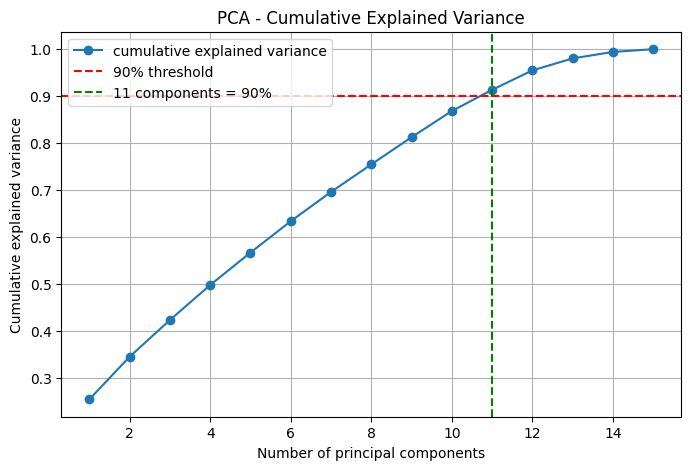

Components needed for >= 90% variance: 11
Explained variance with 11 components: 0.9135


In [9]:
# ==========================================
# C1. Fit PCA (with scaling) + cumulative explained variance plot
# ==========================================
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

pca_full = PCA().fit(X_train_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

# rule: minimum components to reach 90% explained variance
n_components_90 = int(np.argmax(cum_var >= 0.90) + 1)

plt.figure(figsize=(8, 5))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o',
         label='cumulative explained variance')
plt.axhline(0.90, color='red', linestyle='--', label='90% threshold')
plt.axvline(n_components_90, color='green', linestyle='--',
            label=f'{n_components_90} components = 90%')
plt.xlabel('Number of principal components')
plt.ylabel('Cumulative explained variance')
plt.title('PCA - Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

print(f"Components needed for >= 90% variance: {n_components_90}")
print(f"Explained variance with {n_components_90} components: {cum_var[n_components_90-1]:.4f}")

In [10]:
# ----- C2. Evaluate the PCA model (scaler -> PCA -> LogisticRegression) -----
pca_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=n_components_90)),
    ('clf', LogisticRegression(max_iter=1000))
])
pca_pipe.fit(X_train, y_train)

pca_test_acc = accuracy_score(y_test, pca_pipe.predict(X_test))
pca_cv = cross_val_score(pca_pipe, X_train, y_train, cv=5, scoring='accuracy')

print(f"PCA components used : {n_components_90}")
print(f"Explained variance  : {cum_var[n_components_90-1]:.4f}")
print(f"PCA CV Accuracy     : {pca_cv.mean():.4f} (+/- {pca_cv.std():.4f})")
print(f"PCA Test Accuracy   : {pca_test_acc:.4f}")

PCA components used : 11
Explained variance  : 0.9135
PCA CV Accuracy     : 0.5914 (+/- 0.0163)
PCA Test Accuracy   : 0.5819


**Interpretation:** Benefit — PCA keeps information spread across components and needs no manual feature picking, so it clearly beats the 4-feature subsets (test accuracy 0.58 vs 0.52). Drawback — because the features are almost uncorrelated, PCA needs **11 of 15 components** to reach 90% variance (barely any compression), and it still stays below the all-feature baseline (0.62).

### Required Deliverables: comparison table

In [11]:
# ==========================================
# Final comparison table (same metric = Accuracy on the same test set)
# ==========================================
results = pd.DataFrame({
    'Method': ['Baseline (all features)', f'SFS (k={k})', f'SBS (k={k})',
               f'Bidirectional (k={k})', f'PCA ({n_components_90} comps)'],
    'Features/Components': [X.shape[1], k, k, k, n_components_90],
    'Selected': ['all features',
                 ', '.join(sfs_features),
                 ', '.join(sbs_features),
                 ', '.join(bid_features),
                 f'{n_components_90} PCs (90% var)'],
    'Test Accuracy': [baseline_test_acc, sfs_test_acc, sbs_test_acc,
                      bid_test_acc, pca_test_acc]
}).sort_values('Test Accuracy', ascending=False).reset_index(drop=True)

display(results.round(4))

,Method,Features/Components,Selected,Test Accuracy
0,Baseline (all features),15,all features,0.6212
1,PCA (11 comps),11,11 PCs (90% var),0.5819
2,SFS (k=4),4,"popularity, danceability, speechiness, acousti...",0.5238
3,SBS (k=4),4,"popularity, danceability, speechiness, acousti...",0.5238
4,Bidirectional (k=4),4,"acousticness, danceability, popularity, speech...",0.5238


### Final answer
For this 8-genre task, **using all 15 features (baseline) gives the best test accuracy (0.62)**, and every reduction method does worse — so dimensionality reduction does not pay off here. Among the reduction methods, **PCA (11 components, 0.58)** clearly beats the 4-feature subsets from SFS/SBS/Bidirectional (0.52), because it retains far more information (91.4% of variance) instead of throwing away 11 of 15 features. In terms of interpretability, however, SFS/SBS/Bidirectional win: they return 4 concrete, named features, whereas PCA's 11 components are linear combinations that are not directly interpretable. Compute-wise, PCA is the cheapest to fit, SFS/SBS are moderate (a few seconds to ~20 s depending on the machine), and Bidirectional is the most expensive (roughly 2x SFS/SBS) because it re-scores swaps; all sequential methods scale poorly as the feature count grows (roughly quadratic in the number of CV fits).

**Ranking of the four reduction methods** — performance: PCA > SFS ~ SBS ~ Bidirectional; interpretability: SFS ~ SBS ~ Bidirectional > PCA; compute cost: PCA < SFS ~ SBS < Bidirectional.

**Recommendation:** if performance is the goal, use the all-feature baseline; if dimensionality reduction is required, prefer **PCA** (best accuracy/compute among the reductions) and choose the named-feature methods (SFS/SBS/Bidirectional) only when interpretability matters more than a few points of accuracy.

### Optional (runtime + PCA 2D projection)

Runtime (seconds):
  SFS           : 8.2
  SBS           : 9.1
  Bidirectional : 18.5


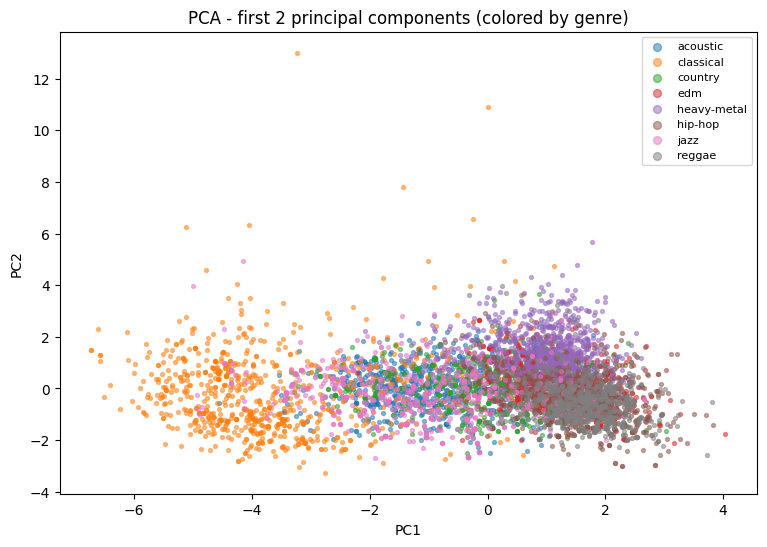

In [12]:
# ----- Optional 1: runtime of SFS vs SBS vs Bidirectional -----
print("Runtime (seconds):")
print(f"  SFS           : {sfs_time:.1f}")
print(f"  SBS           : {sbs_time:.1f}")
print(f"  Bidirectional : {bid_time:.1f}")
# Feasibility: the number of CV fits grows roughly quadratically with the
# number of features, so sequential selection becomes impractical fast
# (e.g. it is fine for ~15 features but explodes for hundreds).

# ----- Optional 2: PCA - first 2 components colored by genre -----
pca2 = PCA(n_components=2)
X_train_2d = pca2.fit_transform(StandardScaler().fit_transform(X_train))

plt.figure(figsize=(9, 6))
for g in sorted(y_train.unique()):
    mask = (y_train == g).values
    plt.scatter(X_train_2d[mask, 0], X_train_2d[mask, 1], s=8, alpha=0.5, label=g)
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('PCA - first 2 principal components (colored by genre)')
plt.legend(markerscale=2, fontsize=8)
plt.show()